# Vectorized UDFs (Apache Arrow & Pandas UDFs)

Spark runs in the JVM, but much of the logic data teams need lives in Python: a pandas transformation, a NumPy
formula, a trained model. A **user-defined function** (UDF) lets Spark call that Python code. The price is data
movement: every value must leave the JVM, enter a Python worker process and come back. How Spark moves those values
(one row at a time, or in columnar **Apache Arrow** batches) decides whether a UDF costs a few percent or most of
the run time.

**After this lesson you can:**

1. Explain why a row-at-a-time Python UDF is slow and what Arrow changes.
2. Measure one computation as a built-in expression, a Python UDF, an Arrow-optimized UDF, a pandas UDF and an
   Arrow UDF.
3. Move data between Spark and pandas with and without Arrow, and measure the difference.
4. Use `applyInPandas` (one pandas DataFrame per group) and `mapInPandas` (a stream of batches).

**Data:** NYC yellow taxi trips, January 2024 (~3M rows).
**Services:** none (Spark runs locally in the notebook).

In [1]:
import os
import shutil
import sys
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import arrow_udf, pandas_udf, udf

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
TMP = Path(tempfile.gettempdir()) / "fzth-m13" / "l05"
shutil.rmtree(TMP, ignore_errors=True); TMP.mkdir(parents=True)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"                 # no hostname warning
LOG4J = TMP / "log4j2.properties"                           # only errors from the JVM, no start-up messages
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\nappender.console.target = SYSTEM_ERR\n"
                 "appender.console.layout.type = PatternLayout\nappender.console.layout.pattern = %p %c{1}: %m%n\n")

spark = (SparkSession.builder.master("local[4]").appName("m13-l05")
         .config("spark.driver.memory", "1500m").config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.driver.extraJavaOptions", f"-Dlog4j.configurationFile=file:{LOG4J} -XX:MaxDirectMemorySize=256m")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
for key in ["spark.sql.execution.arrow.pyspark.enabled", "spark.sql.execution.pythonUDF.arrow.enabled",
            "spark.sql.execution.arrow.maxRecordsPerBatch"]:
    print(f"{key} = {spark.conf.get(key)}")

(spark.read.parquet(str(datasets.taxi("2024-01")))
 .where("tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-02-01'")
 .select("tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount", "total_amount")
 .write.parquet(str(TMP / "trips")))
trips = spark.read.parquet(str(TMP / "trips")).cache()
print(f"trips: {trips.count():,} rows, {trips.rdd.getNumPartitions()} partitions (cached in memory)")

def best_of(fn, reps: int = 2) -> float:
    times = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

def run_sum(df) -> None:
    df.agg(F.sum("tip_pct")).collect()               # forces the computation of every row

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


spark.sql.execution.arrow.pyspark.enabled = true
spark.sql.execution.pythonUDF.arrow.enabled = true
spark.sql.execution.arrow.maxRecordsPerBatch = 10000


trips: 2,964,606 rows, 4 partitions (cached in memory)


## 1. Why Python UDFs Are Slow

A built-in function (`F.when`, `F.col("a") / F.col("b")`) is compiled into the JVM plan; Spark runs it on its own
binary rows without copying. A Python UDF runs in a separate **Python worker process**. Spark must:

1. convert each row from its binary format into Python objects (pickle),
2. send the bytes to the worker over a local socket,
3. call the function **once per row** in the Python interpreter,
4. pickle the result and send it back to the JVM.

**Apache Arrow** is a columnar in-memory format: the values of one column lie next to each other in one buffer,
with a separate validity bitmap for nulls. The JVM and Python (pyarrow, pandas, NumPy) can read the same layout, so
Spark sends a **batch** of 10,000 rows as a few buffers instead of 10,000 pickled tuples, and the function can run
vectorized over whole columns.

| | Python UDF (`@udf`) | Arrow-optimized UDF (`useArrow=True`) | pandas UDF (`@pandas_udf`) | Arrow UDF (`@arrow_udf`) |
| :--- | :--- | :--- | :--- | :--- |
| transfer format | pickled rows | Arrow batches | Arrow batches | Arrow batches |
| your function gets | one row's values | one row's values | `pd.Series` per batch | `pa.Array` per batch |
| function calls per 10k rows | 10,000 | 10,000 | 1 | 1 |

The test computation is the **tip share**: `100 * tip / fare` when the fare is positive, otherwise null.

In [2]:
def tip_pct_py(fare, tip):                        # plain Python, one row per call
    return 100.0 * tip / fare if fare is not None and fare > 0 else None

py_udf = udf(tip_pct_py, "double", useArrow=False)     # classic: pickled rows
arrow_py_udf = udf(tip_pct_py, "double", useArrow=True)  # same function, Arrow transfer

@pandas_udf("double")
def tip_pct_pandas(fare: pd.Series, tip: pd.Series) -> pd.Series:
    return (100.0 * tip / fare).where(fare > 0)

@arrow_udf("double")
def tip_pct_arrow(fare: pa.Array, tip: pa.Array) -> pa.Array:
    return pc.if_else(pc.greater(fare, 0), pc.divide(pc.multiply(tip, 100.0), fare), None)

variants = {
    "built-in expression": F.when(F.col("fare_amount") > 0, 100.0 * F.col("tip_amount") / F.col("fare_amount")),
    "Python UDF": py_udf("fare_amount", "tip_amount"),
    "Arrow-optimized Python UDF": arrow_py_udf("fare_amount", "tip_amount"),
    "pandas UDF": tip_pct_pandas("fare_amount", "tip_amount"),
    "Arrow UDF": tip_pct_arrow("fare_amount", "tip_amount"),
}
rows = []
for name, expr in variants.items():
    df = trips.select(expr.alias("tip_pct"))
    check = df.agg(F.count("tip_pct").alias("non_null"), F.sum("tip_pct").alias("total")).first()
    rows.append({"variant": name, "seconds": round(best_of(lambda: run_sum(df), reps=2), 2),
                 "non-null rows": check.non_null, "sum of tip_pct": round(check.total, 1)})
udfs = pd.DataFrame(rows)
udfs["x built-in"] = (udfs.seconds / udfs.seconds.iloc[0]).round(1)
print(udfs.to_string(index=False))

                   variant  seconds  non-null rows  sum of tip_pct  x built-in
       built-in expression     0.27        2926266      67614708.2         1.0
                Python UDF     2.01        2926266      67614708.2         7.4
Arrow-optimized Python UDF     1.00        2926266      67614708.2         3.7
                pandas UDF     0.50        2926266      67614708.2         1.9
                 Arrow UDF     0.47        2926266      67614708.2         1.7


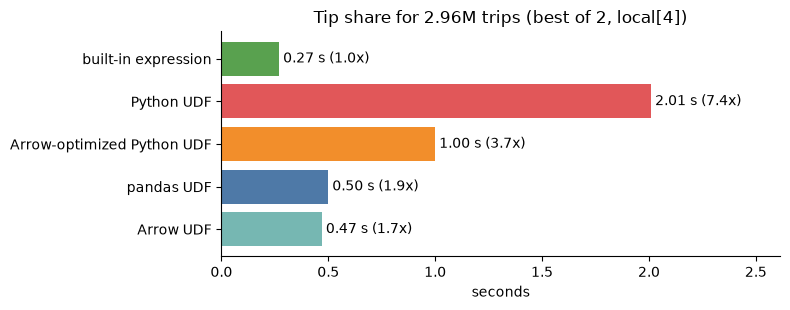

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = ["#59A14F", "#E15759", "#F28E2B", "#4E79A7", "#76B7B2"]
ax.barh(udfs.variant[::-1], udfs.seconds[::-1], color=colors[::-1])
for y, (s, x) in enumerate(zip(udfs.seconds[::-1], udfs["x built-in"][::-1])):
    ax.text(s, y, f" {s:.2f} s ({x}x)", va="center")
ax.set(title="Tip share for 2.96M trips (best of 2, local[4])", xlabel="seconds")
ax.set_xlim(0, udfs.seconds.max() * 1.3)
plt.tight_layout(); plt.show()

*Insight: All five variants return the same 2,926,266 non-null values and the same sum. The row-at-a-time Python
UDF is the slowest (7.4x the built-in time). The Arrow-optimized UDF runs the same Python function but moves the data
in batches (3.7x). The pandas and Arrow UDFs compute on whole columns and come closest to the built-in expression
(1.9x and 1.7x). Local-mode
timings are indicative. The rule: use a built-in function when one exists; when you need Python, write it
vectorized.*

## 2. Spark to pandas and Back

`df.toPandas()` collects a distributed DataFrame into one pandas DataFrame on the driver;
`spark.createDataFrame(pdf)` does the opposite. Without Arrow, both go row by row through Python objects. With
`spark.sql.execution.arrow.pyspark.enabled=true`, Spark sends Arrow batches.

In [4]:
sample = trips.limit(500_000).cache(); sample.count()
rows = []
for arrow in ["false", "true"]:
    spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", arrow)
    t_to = best_of(lambda: sample.toPandas())
    pdf = sample.toPandas()
    small = pdf.head(200_000)
    t_from = best_of(lambda: spark.createDataFrame(small).count())
    rows.append({"Arrow": arrow, "toPandas 500k rows (s)": round(t_to, 2), "createDataFrame 200k rows (s)": round(t_from, 2),
                 "dtypes": dict(pdf.dtypes.astype(str))})
conv = pd.DataFrame(rows)
print(conv.drop(columns="dtypes").to_string(index=False))
print("speed-up toPandas:", round(conv.iloc[0, 1] / conv.iloc[1, 1], 1), "x | createDataFrame:",
      round(conv.iloc[0, 2] / conv.iloc[1, 2], 1), "x")
print("pandas dtypes (Arrow on):", rows[1]["dtypes"])

Arrow  toPandas 500k rows (s)  createDataFrame 200k rows (s)
false                    3.97                           5.90
 true                    0.20                           0.49
speed-up toPandas: 19.8 x | createDataFrame: 12.0 x
pandas dtypes (Arrow on): {'tpep_pickup_datetime': 'datetime64[us]', 'PULocationID': 'int32', 'trip_distance': 'float64', 'fare_amount': 'float64', 'tip_amount': 'float64', 'total_amount': 'float64'}


*Insight: With Arrow, `toPandas` was 19.8x faster (3.97 s to 0.20 s). `createDataFrame` from pandas was 12.0x
faster (5.90 s to 0.49 s), for the same data. `toPandas` still moves every row to the driver: it is for results that fit in driver
memory (aggregates, samples), not for full tables. Keep `spark.sql.execution.arrow.pyspark.enabled=true` in every
PySpark session.*

## 3. Grouped Map: `applyInPandas`

`groupBy(...).applyInPandas(fn, schema)` shuffles the rows so that each group is in one task, then calls `fn` with
the **whole group as one pandas DataFrame**. The function can return any number of rows. Here it fits a small linear
model per pickup zone, `fare = a + b * distance`, with NumPy.

The whole group must fit in the memory of one Python worker. A very large group (a skewed key) is a risk.

In [5]:
fit_schema = "PULocationID int, n long, base_fare double, per_mile double, r2 double"

def fit_zone(pdf: pd.DataFrame) -> pd.DataFrame:
    if len(pdf) < 1000:                            # too few trips for a stable fit: no output row
        return pd.DataFrame(columns=["PULocationID", "n", "base_fare", "per_mile", "r2"])
    x, y = pdf.trip_distance.to_numpy(), pdf.fare_amount.to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (intercept + slope * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return pd.DataFrame({"PULocationID": [pdf.PULocationID.iloc[0]], "n": [len(pdf)],
                         "base_fare": [intercept], "per_mile": [slope], "r2": [r2]})

clean = trips.where("trip_distance BETWEEN 0.5 AND 30 AND fare_amount BETWEEN 3 AND 200")
t0 = time.perf_counter()
fits = (clean.select("PULocationID", "trip_distance", "fare_amount")
        .groupBy("PULocationID").applyInPandas(fit_zone, fit_schema).toPandas())
print(f"{len(fits)} zones with >= 1000 trips, fitted in {time.perf_counter() - t0:.1f} s")
zones = pd.read_csv(str(datasets.fetch("taxi_zone_lookup.csv"))).set_index("LocationID").Zone
fits["zone"] = fits.PULocationID.map(zones)
print(fits.sort_values("n", ascending=False).head(6).round(3).to_string(index=False))

# check one zone against NumPy on the driver
jfk = clean.where("PULocationID = 132").select("trip_distance", "fare_amount").toPandas()
print("JFK check, NumPy on the driver:", np.round(np.polyfit(jfk.trip_distance, jfk.fare_amount, 1)[::-1], 3))

69 zones with >= 1000 trips, fitted in 2.1 s
 PULocationID      n  base_fare  per_mile    r2                         zone
          132 135229      9.894     3.285 0.825                  JFK Airport
          161 134232      6.201     4.005 0.920               Midtown Center
          237 131827      5.483     4.069 0.875        Upper East Side South
          236 125634      5.432     4.012 0.877        Upper East Side North
          162  99969      6.061     4.001 0.908                 Midtown East
          186  99500      6.535     4.151 0.859 Penn Station/Madison Sq West


JFK check, NumPy on the driver: [9.894 3.285]


*Insight: One Python function call per zone fitted the models for all zones with at least 1,000 trips, and the JFK
coefficients match a direct NumPy fit on the driver. JFK has a high base fare and a low slope because most JFK trips
to Manhattan pay a flat fare. The linear model fits worse there: R² is 0.825, against 0.859 to 0.920 for the other
busy zones. A per-group model makes this visible.*

## 4. Streaming Batches: `mapInPandas`

`mapInPandas(fn, schema)` has no shuffle. Each task passes an **iterator** of pandas DataFrames (Arrow batches of up
to `maxRecordsPerBatch` rows) to `fn`, and `fn` yields output DataFrames. This is the usual pattern for batch
inference: load a model once per task, then score batch after batch. The "model" here is the per-zone coefficients
from Section 3.

In [6]:
coef = fits.set_index("PULocationID")[["base_fare", "per_mile"]]

def score(batches):
    model = coef                                   # in real jobs: load the model once per task here
    for pdf in batches:
        m = pdf.join(model, on="PULocationID", how="inner")
        m["predicted"] = m.base_fare + m.per_mile * m.trip_distance
        yield pd.DataFrame({"PULocationID": m.PULocationID, "fare_amount": m.fare_amount,
                            "predicted": m.predicted, "batch_rows": len(pdf)})

scored = clean.select("PULocationID", "trip_distance", "fare_amount").mapInPandas(
    score, "PULocationID int, fare_amount double, predicted double, batch_rows long")
summary = scored.agg(F.count("*").alias("scored"), F.avg(F.abs(F.col("fare_amount") - F.col("predicted"))).alias("mae"),
                     F.max("batch_rows").alias("max_batch")).first()
print(f"scored {summary.scored:,} trips, mean absolute error {summary.mae:.2f} $, largest input batch {summary.max_batch:,} rows")
spark.conf.set("spark.sql.execution.arrow.maxRecordsPerBatch", "2000")
print("with maxRecordsPerBatch=2000:", scored.agg(F.max("batch_rows")).first()[0], "rows per batch")
spark.conf.unset("spark.sql.execution.arrow.maxRecordsPerBatch")

scored 2,712,987 trips, mean absolute error 2.37 $, largest input batch 10,000 rows


with maxRecordsPerBatch=2000: 2000 rows per batch


*Insight: The function saw the data in batches of at most 10,000 rows (the default `maxRecordsPerBatch`), so memory
stays bounded no matter how large the table is. The per-zone linear model predicts the fare with a mean absolute error
of 2.37 $. Smaller batches lower the memory per call; larger batches lower the per-call overhead.*

## 5. Which Tool When

| Need | Use | Why |
| :--- | :--- | :--- |
| the logic exists as a Spark function (`when`, `regexp_extract`, date functions, `percentile_approx`) | built-in function | runs in the JVM, no Python worker, optimized by Catalyst |
| a scalar formula with NumPy or pandas | `@pandas_udf` (Series to Series) | vectorized, Arrow transfer |
| a scalar formula with pyarrow compute | `@arrow_udf` | vectorized, no pandas conversion |
| existing row-by-row Python code you cannot rewrite | `@udf(useArrow=True)` | same code, faster transfer |
| one model or statistic **per group** | `groupBy().applyInPandas` | each group as one DataFrame; group must fit in memory |
| batch inference, row-wise transforms with set-up cost | `mapInPandas` | no shuffle, iterator of batches, load once per task |
| results that fit in driver memory | `toPandas()` with Arrow on | for charts and small tables only |
| plain `@udf` without Arrow | rarely | the slowest path in Section 1 |

## Real-World Use Case or Analogy

A row-at-a-time UDF is like a shop that sends every item to the customer in a separate parcel: each parcel needs a
box, a label and a trip. Arrow batches are a pallet: the same goods, one trip, and the customer unpacks with a
forklift (vectorized code) instead of by hand.

Data teams use pandas UDFs and `mapInPandas` to run scikit-learn or PyTorch models over billions of rows (batch
scoring), and `applyInPandas` to train one forecasting model per store or per product. Libraries such as Spark's own
pandas API on Spark and many feature-engineering tools are built on these Arrow-based functions.

In [7]:
trips.unpersist(); sample.unpersist()
spark.stop()